# Laboratorio 3. Arquitectura Lakehouse y modelado predictivo de variaciones delictivas en Bogotá con datos SIEDCO y Apache Spark

**Integrantes:**  
Adrian Grateron  
Jhonatan Smith Doncel  
Jorge Emmanuel Marín  

## Introducción

En este laboratorio trabajamos con información histórica de hechos delictivos registrada en SIEDCO y construimos un flujo completo de procesamiento en Databricks. El propósito es llevar el archivo original desde una capa de almacenamiento trazable hasta un conjunto de datos preparado para analítica predictiva.

La arquitectura se organiza en tres capas. **Bronze** conserva la información recibida y agrega trazabilidad de la ingestión. **Silver** limpia y organiza los registros para construir series mensuales comparables por localidad y tipo de hecho. **Gold** incorpora variables que resumen el comportamiento reciente de cada serie mediante funciones de ventana de Spark.

A partir de Gold se plantea un problema de clasificación: identificar si el número de casos de una combinación localidad–hecho tendrá, durante el mes siguiente, un cambio alto frente a su propio comportamiento histórico. Para responder esta pregunta se comparan una Regresión Logística y un Random Forest con Spark ML.

El ejercicio se concentra en integrar arquitectura Lakehouse, procesamiento distribuido, ingeniería de características temporales y aprendizaje automático. No pretende anticipar delitos individuales ni producir alertas operativas.

## Fuente de información

**Fuente:** SIEDCO – Secretaría Distrital de Seguridad, Convivencia y Justicia  
**Archivo:** `SIEDCO.csv`  
**Fecha de consulta registrada en la fuente:** 03/08/2026  
**Datos actualizados hasta:** 31/07/2026  
**Período utilizado:** enero de 2018 a julio de 2026  

Cada fila del archivo corresponde a una combinación de características como sexo, hecho, localidad, arma empleada, rango vital y rango del día. La columna `CANTIDAD` indica cuántos registros corresponden a esa combinación.

Las columnas `Fecha de consulta` y `Datos actualizados hasta` se conservan únicamente en Bronze como metadatos de la fuente. No se utilizan en Silver, Gold ni en los modelos.

El análisis se limita a julio de 2026 porque es el último mes completo disponible.

### Problema analítico

La pregunta que guía el ejercicio es:

> **¿Es posible identificar condiciones asociadas con una variación alta en el número de casos del mes siguiente utilizando el comportamiento reciente de cada combinación localidad–hecho?**

La unidad temporal es mensual. Cada serie está definida por una combinación de localidad y tipo de hecho, por ejemplo:

`KENNEDY | HURTO A PERSONAS`

Como algunas series pueden tener meses con cero casos, no utilizamos una variación porcentual tradicional. En su lugar calculamos un cambio logarítmico:

```text
change_km = ln(1 + cases_t) - ln(1 + cases_t-k)
```

`cases_t` es el número de casos del mes actual y `cases_t-k` el observado uno, tres o siete meses atrás.

### Variable Objetivo
La variable objetivo se construye a partir del valor absoluto del cambio del mes siguiente. Esto significa que una subida fuerte y una caída fuerte pueden clasificarse como alta variación. El modelo estudia cambios inusualmente grandes, no solamente aumentos.

El umbral de alta variación corresponde al percentil 75 de cada serie y se calcula exclusivamente con el conjunto de entrenamiento. El mismo umbral se aplica posteriormente al conjunto de prueba.

### Arquitectura utilizada

El flujo mantiene una separación clara entre almacenamiento, preparación y modelado:

**Bronze:** copia trazable del archivo recibido.  
**Silver:** limpieza, validación y construcción del panel mensual.  
**Gold:** variables temporales construidas con funciones de ventana.  
**Spark ML:** preparación del vector, entrenamiento y evaluación de los clasificadores.

Las tres capas se almacenan como tablas Delta dentro de Databricks.

### 1. Configuración general

Se definen las rutas, las tablas Delta y los parámetros que se utilizarán durante todo el laboratorio.

In [0]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

from pyspark.ml import Pipeline
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.feature import OneHotEncoder, StringIndexer, VectorAssembler
from pyspark.ml.functions import vector_to_array
from pyspark.sql.types import (
    DoubleType,
    LongType,
    StringType,
    StructField,
    StructType,
)
import pandas as pd
import plotly.express as px
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import plotly.graph_objects as go

CATALOG = "workspace"
SCHEMA = "bigdata"

CSV_INPUT_PATH = (
    "/Volumes/workspace/bigdata/lab_files/SIEDCO.csv"
)

BRONZE_TABLE = f"{CATALOG}.{SCHEMA}.siedco_lab3_bronze"
SILVER_TABLE = f"{CATALOG}.{SCHEMA}.siedco_lab3_silver"
GOLD_TABLE = f"{CATALOG}.{SCHEMA}.siedco_lab3_gold"

TRAIN_RATIO = 0.80
VARIATION_PERCENTILE = 0.75

# En la serie mensual se usa el primer día como identificador técnico del mes.
LAST_COMPLETE_MONTH = "2026-07-01"

# Evita modelar combinaciones localidad-hecho extremadamente esporádicas.
MIN_ACTIVE_MONTHS = 80

spark.sql(f"CREATE SCHEMA IF NOT EXISTS {CATALOG}.{SCHEMA}")

print(f"Fuente CSV: {CSV_INPUT_PATH}")
print(f"Bronze: {BRONZE_TABLE}")
print(f"Silver: {SILVER_TABLE}")
print(f"Gold: {GOLD_TABLE}")
print("Corte de información: 31/07/2026")

Fuente CSV: /Volumes/workspace/bigdata/lab_files/SIEDCO.csv
Bronze: workspace.bigdata.siedco_lab3_bronze
Silver: workspace.bigdata.siedco_lab3_silver
Gold: workspace.bigdata.siedco_lab3_gold
Corte de información: 31/07/2026


### 2. Lectura del archivo fuente

El archivo está separado por punto y coma. Se carga con Spark, se revisa el esquema y se inspeccionan los primeros registros antes de iniciar las transformaciones.

In [0]:
df_raw = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .option("sep", ";")
    .csv(CSV_INPUT_PATH)
)

df_raw.printSchema()
display(df_raw.limit(10))
print(f"Total de registros recibidos: {df_raw.count():,}")

root
 |-- SEXO: string (nullable = true)
 |-- ANIO: integer (nullable = true)
 |-- MES: integer (nullable = true)
 |-- HECHO: string (nullable = true)
 |-- LOCALIDAD: string (nullable = true)
 |-- COD_LOCALIDAD: integer (nullable = true)
 |-- ARMA_EMPLEADA: string (nullable = true)
 |-- RANGO_VITAL: string (nullable = true)
 |-- RANGO_DEL_DIA: string (nullable = true)
 |-- CANTIDAD: integer (nullable = true)
 |-- Fecha de consulta: string (nullable = true)
 |-- Datos actualizados hasta: date (nullable = true)



SEXO,ANIO,MES,HECHO,LOCALIDAD,COD_LOCALIDAD,ARMA_EMPLEADA,RANGO_VITAL,RANGO_DEL_DIA,CANTIDAD,Fecha de consulta,Datos actualizados hasta
MASCULINO,2018,1,HURTO A PERSONAS,PUENTE ARANDA,16,SIN EMPLEO DE ARMAS,ADULTEZ,MAÑANA,24,3/08/2026,2026-07-31
FEMENINO,2018,1,HURTO A RESIDENCIAS,USME,5,PALANCAS,ADULTEZ,NOCHE,1,null,null
MASCULINO,2018,1,LESIONES PERSONALES,KENNEDY,8,CONTUNDENTES,ADULTEZ,MADRUGADA,29,null,null
FEMENINO,2018,1,HURTO A RESIDENCIAS,TEUSAQUILLO,13,PALANCAS,ADULTEZ,NOCHE,1,null,null
FEMENINO,2018,1,HURTO A PERSONAS,KENNEDY,8,ARMA DE FUEGO,ADULTEZ,NOCHE,10,null,null
FEMENINO,2018,1,HURTO A RESIDENCIAS,ANTONIO NARIÑO,15,PALANCAS,ADULTEZ,TARDE,1,null,null
MASCULINO,2018,1,HURTO A PERSONAS,LOS MÁRTIRES,14,SIN EMPLEO DE ARMAS,ADULTEZ,MAÑANA,16,null,null
FEMENINO,2018,1,VIOLENCIA INTRAFAMILIAR,SAN CRISTÓBAL,4,NO REPORTADO,ADULTEZ,MADRUGADA,9,null,null
FEMENINO,2018,1,DELITOS SEXUALES,BARRIOS UNIDOS,12,NO REPORTADO,ADULTEZ,MADRUGADA,2,null,null
FEMENINO,2018,1,VIOLENCIA INTRAFAMILIAR,SUBA,11,SIN EMPLEO DE ARMAS,ADOLESCENCIA,MADRUGADA,5,null,null


Total de registros recibidos: 368,651


### 3. Capa Bronze

Bronze conserva los datos recibidos con transformaciones mínimas y agrega información de trazabilidad.

Las dos columnas de metadatos que contienen espacios se renombran únicamente para garantizar compatibilidad con Delta Lake. Sus valores no se modifican.

In [0]:
df_bronze = (
    df_raw
    .withColumnRenamed("Fecha de consulta", "fecha_consulta")
    .withColumnRenamed(
        "Datos actualizados hasta",
        "datos_actualizados_hasta",
    )
    .withColumn("ingestion_timestamp", F.current_timestamp())
    .withColumn("record_source", F.lit("SIEDCO_Policia_Nacional"))
)

(
    df_bronze.write
    .format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .saveAsTable(BRONZE_TABLE)
)

print(f"Tabla Bronze creada: {BRONZE_TABLE}")
display(spark.table(BRONZE_TABLE).limit(10))

Tabla Bronze creada: workspace.bigdata.siedco_lab3_bronze


SEXO,ANIO,MES,HECHO,LOCALIDAD,COD_LOCALIDAD,ARMA_EMPLEADA,RANGO_VITAL,RANGO_DEL_DIA,CANTIDAD,fecha_consulta,datos_actualizados_hasta,ingestion_timestamp,record_source
MASCULINO,2018,1,HURTO A PERSONAS,PUENTE ARANDA,16,SIN EMPLEO DE ARMAS,ADULTEZ,MAÑANA,24,3/08/2026,2026-07-31,2026-09-23T03:19:39.131Z,SIEDCO_Policia_Nacional
FEMENINO,2018,1,HURTO A RESIDENCIAS,USME,5,PALANCAS,ADULTEZ,NOCHE,1,null,null,2026-09-23T03:19:39.131Z,SIEDCO_Policia_Nacional
MASCULINO,2018,1,LESIONES PERSONALES,KENNEDY,8,CONTUNDENTES,ADULTEZ,MADRUGADA,29,null,null,2026-09-23T03:19:39.131Z,SIEDCO_Policia_Nacional
FEMENINO,2018,1,HURTO A RESIDENCIAS,TEUSAQUILLO,13,PALANCAS,ADULTEZ,NOCHE,1,null,null,2026-09-23T03:19:39.131Z,SIEDCO_Policia_Nacional
FEMENINO,2018,1,HURTO A PERSONAS,KENNEDY,8,ARMA DE FUEGO,ADULTEZ,NOCHE,10,null,null,2026-09-23T03:19:39.131Z,SIEDCO_Policia_Nacional
FEMENINO,2018,1,HURTO A RESIDENCIAS,ANTONIO NARIÑO,15,PALANCAS,ADULTEZ,TARDE,1,null,null,2026-09-23T03:19:39.131Z,SIEDCO_Policia_Nacional
MASCULINO,2018,1,HURTO A PERSONAS,LOS MÁRTIRES,14,SIN EMPLEO DE ARMAS,ADULTEZ,MAÑANA,16,null,null,2026-09-23T03:19:39.131Z,SIEDCO_Policia_Nacional
FEMENINO,2018,1,VIOLENCIA INTRAFAMILIAR,SAN CRISTÓBAL,4,NO REPORTADO,ADULTEZ,MADRUGADA,9,null,null,2026-09-23T03:19:39.131Z,SIEDCO_Policia_Nacional
FEMENINO,2018,1,DELITOS SEXUALES,BARRIOS UNIDOS,12,NO REPORTADO,ADULTEZ,MADRUGADA,2,null,null,2026-09-23T03:19:39.131Z,SIEDCO_Policia_Nacional
FEMENINO,2018,1,VIOLENCIA INTRAFAMILIAR,SUBA,11,SIN EMPLEO DE ARMAS,ADOLESCENCIA,MADRUGADA,5,null,null,2026-09-23T03:19:39.131Z,SIEDCO_Policia_Nacional


### 4. Capa Silver

En esta capa:
- Tipamos columnas
- Eliminamos registros invalidos
- Eliminamos duplicados
- Generamos variables temporales básicas


SIEDCO no viene con una fila por caso. Una misma combinación localidad–hecho puede aparecer varias veces en el mismo mes porque también está desagregada por sexo, arma, rango vital y rango del día.

Por eso, antes de construir la serie temporal, se validan tipos y valores y luego se agregan los registros para obtener una sola observación mensual por localidad y tipo de hecho.

Además del total de casos, se conservan dos medidas de composición que sirven como equivalentes analíticos de variables auxiliares en una serie temporal:

- `night_cases`: casos registrados en la franja `NOCHE`;
- `firearm_cases`: casos con `ARMA DE FUEGO`.

No se construye día de la semana porque la fuente tiene periodicidad mensual. En su lugar se utilizan año, mes y trimestre.

In [0]:
bronze_df = spark.table(BRONZE_TABLE)

df_clean = (
    bronze_df
    .withColumn("sexo", F.upper(F.trim(F.col("SEXO"))))
    .withColumn("anio", F.col("ANIO").cast("int"))
    .withColumn("mes", F.col("MES").cast("int"))
    .withColumn("hecho", F.upper(F.trim(F.col("HECHO"))))
    .withColumn("localidad", F.upper(F.trim(F.col("LOCALIDAD"))))
    .withColumn("cod_localidad", F.col("COD_LOCALIDAD").cast("int"))
    .withColumn("arma_empleada", F.upper(F.trim(F.col("ARMA_EMPLEADA"))))
    .withColumn("rango_vital", F.upper(F.trim(F.col("RANGO_VITAL"))))
    .withColumn("rango_del_dia", F.upper(F.trim(F.col("RANGO_DEL_DIA"))))
    .withColumn("cantidad", F.col("CANTIDAD").cast("long"))
    .filter(F.col("anio").isNotNull())
    .filter(F.col("mes").between(1, 12))
    .filter(F.col("hecho").isNotNull())
    .filter(F.col("localidad").isNotNull())
    .filter(F.col("cod_localidad").isNotNull())
    .filter(F.col("cantidad") > 0)
    .withColumn(
        "date",
        F.make_date(F.col("anio"), F.col("mes"), F.lit(1)),
    )
    .filter(
        F.col("date") <= F.to_date(F.lit(LAST_COMPLETE_MONTH))
    )
)

monthly_observed = (
    df_clean
    .filter(F.col("localidad") != "SIN LOCALIZACION")
    .groupBy(
        "localidad",
        "cod_localidad",
        "hecho",
        "date",
    )
    .agg(
        F.sum("cantidad").cast("long").alias("cases"),
        F.sum(
            F.when(
                F.col("rango_del_dia") == "NOCHE",
                F.col("cantidad"),
            ).otherwise(F.lit(0))
        ).cast("long").alias("night_cases"),
        F.sum(
            F.when(
                F.col("arma_empleada") == "ARMA DE FUEGO",
                F.col("cantidad"),
            ).otherwise(F.lit(0))
        ).cast("long").alias("firearm_cases"),
    )
)

print(f"Registros válidos de la fuente: {df_clean.count():,}")
display(monthly_observed.limit(10))

Registros válidos de la fuente: 368,651


localidad,cod_localidad,hecho,date,cases,night_cases,firearm_cases
PUENTE ARANDA,16,HURTO A PERSONAS,2018-01-01,329,67,49
USME,5,HURTO A RESIDENCIAS,2018-01-01,41,14,5
KENNEDY,8,LESIONES PERSONALES,2018-01-01,241,47,7
TEUSAQUILLO,13,HURTO A RESIDENCIAS,2018-01-01,40,6,1
KENNEDY,8,HURTO A PERSONAS,2018-01-01,760,212,108
ANTONIO NARIÑO,15,HURTO A RESIDENCIAS,2018-01-01,11,1,0
LOS MÁRTIRES,14,HURTO A PERSONAS,2018-01-01,277,68,31
SAN CRISTÓBAL,4,VIOLENCIA INTRAFAMILIAR,2018-01-01,210,28,2
BARRIOS UNIDOS,12,DELITOS SEXUALES,2018-01-01,9,2,0
SUBA,11,VIOLENCIA INTRAFAMILIAR,2018-01-01,294,19,0


#### 4.1. Cobertura temporal y panel mensual

Las funciones `lag()` y `lead()` deben avanzar entre meses consecutivos. Si una serie no aparece en un mes, no queremos que Spark salte directamente al siguiente registro disponible.

Primero se conservan las combinaciones localidad–hecho con al menos 80 meses con registros positivos. Luego se construye un calendario mensual completo entre enero de 2018 y julio de 2026 y se asigna cero a los meses sin registros.

Este paso es necesario porque el archivo original contiene únicamente combinaciones que tuvieron registros; no trae explícitamente las combinaciones con cantidad igual a cero.

In [0]:
series_coverage = (
    monthly_observed
    .groupBy(
        "localidad",
        "cod_localidad",
        "hecho",
    )
    .agg(
        F.countDistinct("date").alias("active_months"),
        F.sum("cases").alias("total_cases"),
        F.min("date").alias("first_date"),
        F.max("date").alias("last_date"),
    )
)

eligible_series = (
    series_coverage
    .filter(F.col("active_months") >= MIN_ACTIVE_MONTHS)
    .select(
        "localidad",
        "cod_localidad",
        "hecho",
    )
    .withColumn(
        "series_id",
        F.concat_ws(
            " | ",
            F.col("localidad"),
            F.col("hecho"),
        ),
    )
)

print(f"Series localidad-hecho elegibles: {eligible_series.count():,}")

date_limits = (
    monthly_observed
    .agg(
        F.min("date").alias("min_date"),
        F.max("date").alias("max_date"),
    )
    .first()
)

min_date = date_limits["min_date"]
max_date = date_limits["max_date"]

calendar_df = spark.sql(
    f"""
    SELECT explode(
        sequence(
            to_date('{min_date}'),
            to_date('{max_date}'),
            interval 1 month
        )
    ) AS date
    """
)

series_dimension = (
    eligible_series
    .select(
        "series_id",
        "localidad",
        "cod_localidad",
        "hecho",
    )
    .distinct()
)

monthly_eligible = (
    monthly_observed
    .join(
        eligible_series,
        on=["localidad", "cod_localidad", "hecho"],
        how="inner",
    )
)

df_silver = (
    series_dimension
    .crossJoin(calendar_df)
    .join(
        monthly_eligible,
        on=[
            "series_id",
            "localidad",
            "cod_localidad",
            "hecho",
            "date",
        ],
        how="left",
    )
    .fillna(
        0,
        subset=[
            "cases",
            "night_cases",
            "firearm_cases",
        ],
    )
    .dropDuplicates(["series_id", "date"])
    .withColumn("year", F.year("date"))
    .withColumn("month", F.month("date"))
    .withColumn("quarter", F.quarter("date"))
)

(
    df_silver.write
    .format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .saveAsTable(SILVER_TABLE)
)

print(f"Tabla Silver creada: {SILVER_TABLE}")
print(f"Registros Silver: {df_silver.count():,}")

Series localidad-hecho elegibles: 182
Tabla Silver creada: workspace.bigdata.siedco_lab3_silver
Registros Silver: 18,746


#### 4.2. Validación de cobertura temporal y valores nulos

Se revisa que cada serie tenga una secuencia mensual completa y que las variables esenciales no contengan valores nulos.

In [0]:
display(
    df_silver
    .groupBy("series_id")
    .agg(
        F.count("*").alias("records"),
        F.min("date").alias("first_date"),
        F.max("date").alias("last_date"),
        F.round(F.avg("cases"), 2).alias("avg_cases"),
    )
    .orderBy("series_id")
)

null_columns = [
    "series_id",
    "localidad",
    "hecho",
    "date",
    "cases",
    "night_cases",
    "firearm_cases",
]

display(
    df_silver.agg(
        *[
            F.sum(
                F.when(F.col(column).isNull(), 1).otherwise(0)
            ).alias(column)
            for column in null_columns
        ]
    )
)

series_id,records,first_date,last_date,avg_cases
ANTONIO NARIÑO | DELITOS SEXUALES,103,2018-01-01,2026-07-01,7.69
ANTONIO NARIÑO | EXTORSION,103,2018-01-01,2026-07-01,1.92
ANTONIO NARIÑO | HURTO A COMERCIO,103,2018-01-01,2026-07-01,36.87
ANTONIO NARIÑO | HURTO A PERSONAS,103,2018-01-01,2026-07-01,197.38
ANTONIO NARIÑO | HURTO A RESIDENCIAS,103,2018-01-01,2026-07-01,10.46
ANTONIO NARIÑO | HURTO AUTOMOTORES,103,2018-01-01,2026-07-01,9.25
ANTONIO NARIÑO | HURTO MOTOCICLETAS,103,2018-01-01,2026-07-01,8.18
ANTONIO NARIÑO | LESIONES PERSONALES,103,2018-01-01,2026-07-01,30.48
ANTONIO NARIÑO | VIOLENCIA INTRAFAMILIAR,103,2018-01-01,2026-07-01,38.68
BARRIOS UNIDOS | DELITOS SEXUALES,103,2018-01-01,2026-07-01,12.54


series_id,localidad,hecho,date,cases,night_cases,firearm_cases
0,0,0,0,0,0,0


### 5. Capa Gold: ingeniería de características temporales

A partir de Silver se construyen variables que describen el comportamiento reciente de cada serie. Se utiliza `Window.partitionBy("series_id").orderBy("date")`, de manera que cada combinación localidad–hecho se procesa de forma independiente y en orden cronológico.

**HECHO**:

Durante los meses 6 y 8 se evidencia un incremento atípico en las transacciones, lo cual afecta las métricas agregadas y las medias móviles calculadas para dichos periodos.

In [0]:
df = spark.table(SILVER_TABLE)
w_order = Window.partitionBy("series_id").orderBy("date")

df_features = (
    df
    .withColumn("lag_cases_1", F.lag("cases", 1).over(w_order))
    .withColumn("lag_cases_3", F.lag("cases", 3).over(w_order))
    .withColumn("lag_cases_7", F.lag("cases", 7).over(w_order))
    .withColumn("lag_night_cases_1", F.lag("night_cases", 1).over(w_order))
    .withColumn("lag_firearm_cases_1", F.lag("firearm_cases", 1).over(w_order))
)

#### 5.1. Cambios de 1, 3 y 7 meses

En datos de precios es habitual utilizar retornos porcentuales. En SIEDCO trabajamos con conteos y algunas series pueden tomar el valor cero, por lo que una variación porcentual produciría divisiones por cero.

Se usa entonces una diferencia logarítmica:

```text
change_1m = ln(1 + cases_t) - ln(1 + cases_t-1)
change_3m = ln(1 + cases_t) - ln(1 + cases_t-3)
change_7m = ln(1 + cases_t) - ln(1 + cases_t-7)
```

In [0]:
def safe_divide(numerator, denominator):
    """Divide dos columnas evitando divisiones por cero."""
    return F.when(
        denominator.isNotNull() & (denominator != 0),
        numerator / denominator,
    )


def log_change(current, previous):
    """Calcula ln(1 + actual) - ln(1 + previo)."""
    return F.when(
        current.isNotNull() & previous.isNotNull(),
        F.log(current.cast("double") + F.lit(1.0))
        - F.log(previous.cast("double") + F.lit(1.0)),
    )


df_features = (
    df_features
    .withColumn(
        "change_1m",
        log_change(F.col("cases"), F.col("lag_cases_1")),
    )
    .withColumn(
        "change_3m",
        log_change(F.col("cases"), F.col("lag_cases_3")),
    )
    .withColumn(
        "change_7m",
        log_change(F.col("cases"), F.col("lag_cases_7")),
    )
)

#### 5.2. Medias móviles y variabilidad histórica

Se mantienen ventanas de 3, 7 y 14 períodos. En este caso cada período corresponde a un mes.

Las medias móviles resumen el nivel reciente de casos y la desviación estándar del cambio mensual representa la variabilidad histórica de la serie.

**Análisis de los Meses 6 y 8:**
En estos periodos se observa una desviación significativa respecto al comportamiento regular de la serie temporal. Las medias móviles de 3 y 6 meses capturan este comportamiento ascendente, lo que permite evaluar la sensibilidad del modelo ante picos de demanda o variaciones estacionales pronunciadas.

In [0]:
w3 = Window.partitionBy("series_id").orderBy("date").rowsBetween(-2, 0)
w7 = Window.partitionBy("series_id").orderBy("date").rowsBetween(-6, 0)
w14 = Window.partitionBy("series_id").orderBy("date").rowsBetween(-13, 0)

df_features = (
    df_features
    .withColumn("ma_3", F.avg("cases").over(w3))
    .withColumn("ma_7", F.avg("cases").over(w7))
    .withColumn("ma_14", F.avg("cases").over(w14))
    .withColumn("volatility_3m", F.stddev("change_1m").over(w3))
    .withColumn("volatility_7m", F.stddev("change_1m").over(w7))
    .withColumn("volatility_14m", F.stddev("change_1m").over(w14))
    .withColumn("night_cases_ma_7", F.avg("night_cases").over(w7))
)

#### 5.3. Variables relativas

Además del total mensual, se incorporan cambios en los casos nocturnos y en los registros con arma de fuego. También se compara el nivel actual con sus medias móviles.

Estas variables permiten representar tanto la magnitud del fenómeno como cambios recientes en su composición.

In [0]:
df_features = (
    df_features
    .withColumn(
        "night_cases_change_1m",
        log_change(
            F.col("night_cases"),
            F.col("lag_night_cases_1"),
        ),
    )
    .withColumn(
        "firearm_cases_change_1m",
        log_change(
            F.col("firearm_cases"),
            F.col("lag_firearm_cases_1"),
        ),
    )
    .withColumn(
        "night_cases_vs_ma_7",
        safe_divide(
            F.col("night_cases"),
            F.col("night_cases_ma_7"),
        ),
    )
    .withColumn(
        "cases_vs_ma_7",
        safe_divide(F.col("cases"), F.col("ma_7")),
    )
    .withColumn(
        "cases_vs_ma_14",
        safe_divide(F.col("cases"), F.col("ma_14")),
    )
)

#### 5.4. Construcción del comportamiento futuro

Se utiliza `lead()` para recuperar el número de casos del mes inmediatamente siguiente.

```text
change_next_month = ln(1 + next_cases) - ln(1 + cases)
abs_change_next_month = valor absoluto de change_next_month
```

`abs_change_next_month` se utiliza únicamente para construir la variable objetivo. No forma parte de las características entregadas a los modelos.

También se exige que `next_date` corresponda exactamente al mes calendario siguiente.

In [0]:
df_features = (
    df_features
    .withColumn("next_date", F.lead("date", 1).over(w_order))
    .withColumn("next_cases", F.lead("cases", 1).over(w_order))
    .withColumn(
        "change_next_month",
        log_change(F.col("next_cases"), F.col("cases")),
    )
    .withColumn(
        "abs_change_next_month",
        F.abs(F.col("change_next_month")),
    )
)

# Garantiza que la siguiente observación corresponda al mes calendario siguiente.
df_features = df_features.filter(
    F.col("next_date") == F.add_months(F.col("date"), 1)
)

#### 5.5. Selección de variables del modelado

Se conservan trece características, siguiendo la misma lógica de trabajar con calendario, cambios recientes, volatilidad histórica, variables auxiliares y relaciones frente a medias móviles.

In [0]:
feature_cols = [
    "month",
    "quarter",
    "change_1m",
    "change_3m",
    "change_7m",
    "volatility_3m",
    "volatility_7m",
    "volatility_14m",
    "night_cases_change_1m",
    "firearm_cases_change_1m",
    "night_cases_vs_ma_7",
    "cases_vs_ma_7",
    "cases_vs_ma_14",
]

df_gold = df_features

for column in feature_cols:
    df_gold = df_gold.filter(F.col(column).isNotNull())

df_gold = df_gold.filter(F.col("abs_change_next_month").isNotNull())

(
    df_gold.write
    .format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .saveAsTable(GOLD_TABLE)
)

print(f"Tabla Gold creada: {GOLD_TABLE}")
print(f"Registros Gold: {df_gold.count():,}")

Tabla Gold creada: workspace.bigdata.siedco_lab3_gold
Registros Gold: 17,229


### 6. Consultas y visualizaciones sobre Gold

Se realizan consultas sobre la tabla Gold para revisar el comportamiento de los hechos y de una serie específica antes de pasar al modelado.

In [0]:
display(
    spark.sql(
        f"""
        SELECT
            hecho,
            COUNT(*) AS records,
            ROUND(AVG(ABS(change_1m)), 6) AS avg_abs_change_1m,
            ROUND(AVG(volatility_7m), 6) AS avg_volatility_7m,
            ROUND(AVG(cases_vs_ma_7), 4) AS avg_cases_vs_ma_7
        FROM {GOLD_TABLE}
        GROUP BY hecho
        ORDER BY avg_volatility_7m DESC
        """
    )
)

hecho,records,avg_abs_change_1m,avg_volatility_7m,avg_cases_vs_ma_7
HOMICIDIOS,1329,0.488198,0.640879,1.0076
EXTORSION,1655,0.481404,0.635313,1.0456
HURTO AUTOMOTORES,1710,0.378884,0.495686,0.9985
DELITOS SEXUALES,1800,0.355035,0.455284,1.021
HURTO MOTOCICLETAS,1710,0.347295,0.447795,1.0139
HURTO A RESIDENCIAS,1805,0.311669,0.395796,0.992
VIOLENCIA INTRAFAMILIAR,1805,0.273697,0.365375,1.0269
HURTO A COMERCIO,1805,0.265297,0.343226,0.982
LESIONES PERSONALES,1805,0.233588,0.303327,0.9977
HURTO A PERSONAS,1805,0.165003,0.219681,1.0088


In [0]:
display(
    spark.sql(
        f"""
        SELECT
            series_id,
            date,
            cases,
            change_1m,
            change_7m,
            volatility_7m,
            cases_vs_ma_7
        FROM {GOLD_TABLE}
        WHERE localidad = 'KENNEDY'
          AND hecho = 'HURTO A PERSONAS'
        ORDER BY date
        """
    )
)

series_id,date,cases,change_1m,change_7m,volatility_7m,cases_vs_ma_7
KENNEDY | HURTO A PERSONAS,2018-08-01,1024,0.14460290926292974,0.2978145337108229,0.11564746153242939,1.1401304278670272
KENNEDY | HURTO A PERSONAS,2018-09-01,1016,-0.007835495523949021,0.24501321020417688,0.11717512265591148,1.0928088506453597
KENNEDY | HURTO A PERSONAS,2018-10-01,1056,0.038577589821677805,0.2735907166912712,0.1166555356410224,1.0933293891436178
KENNEDY | HURTO A PERSONAS,2018-11-01,988,-0.06649565424752524,0.07558685936624787,0.11449547159582024,1.0121469339967804
KENNEDY | HURTO A PERSONAS,2018-12-01,974,-0.014256860624865197,-0.04805729495377875,0.10597108351663062,1.0048636698599853
KENNEDY | HURTO A PERSONAS,2019-01-01,869,-0.1139442593492177,0.032713197406303074,0.08428694343370399,0.8928519007779245
KENNEDY | HURTO A PERSONAS,2019-02-01,1045,0.184235432976239,0.1648836623152894,0.10811008490438262,1.0491967871485943
KENNEDY | HURTO A PERSONAS,2019-03-01,1172,0.11459120402860723,0.1348719570809669,0.10298305168500742,1.152247191011236
KENNEDY | HURTO A PERSONAS,2019-04-01,1070,-0.0909717782057271,0.0517356743991888,0.11110339737239884,1.044047950933928
KENNEDY | HURTO A PERSONAS,2019-05-01,1080,0.009293747191459367,0.022451831768970365,0.11028167663733643,1.0502917477076967


#### 6.1. Evolución mensual y comparación por hecho

La primera visualización resume la evolución mensual de los casos incluidos en Gold. La segunda muestra las diferencias de escala entre los tipos de hecho.

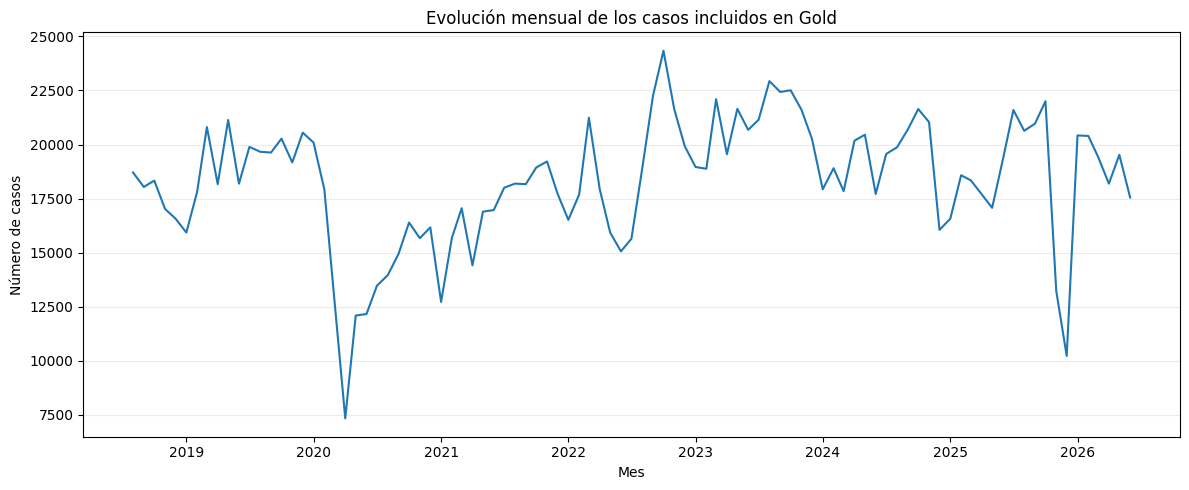

In [0]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

monthly_trend_pd = (
    spark.table(GOLD_TABLE)
    .groupBy("date")
    .agg(F.sum("cases").alias("total_cases"))
    .orderBy("date")
    .toPandas()
)

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_trend_pd["date"],
    monthly_trend_pd["total_cases"],
)
plt.title("Evolución mensual de los casos incluidos en Gold")
plt.xlabel("Mes")
plt.ylabel("Número de casos")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

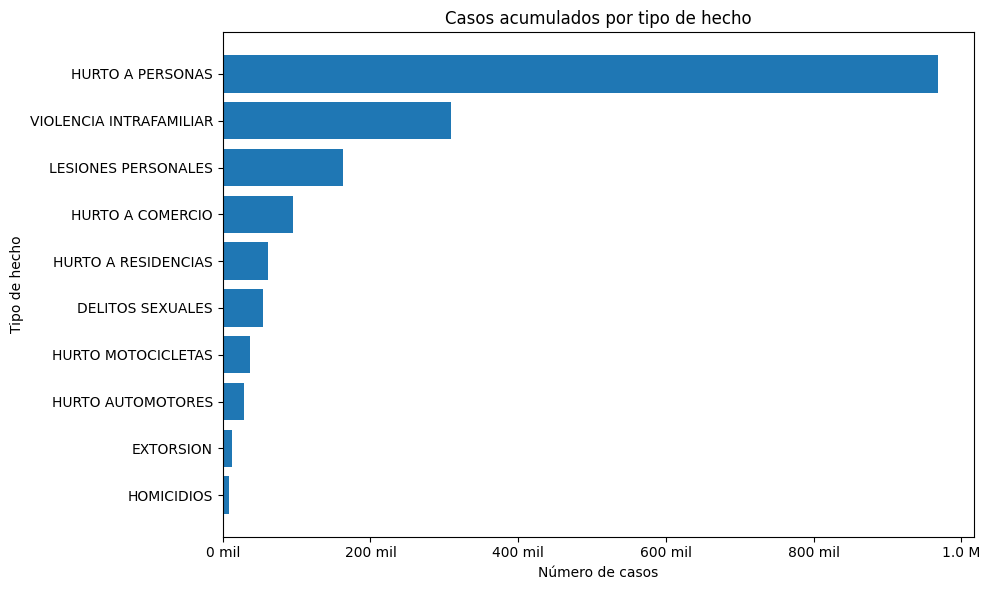

In [0]:
cases_by_hecho_pd = (
    spark.table(GOLD_TABLE)
    .groupBy("hecho")
    .agg(F.sum("cases").alias("total_cases"))
    .orderBy(F.desc("total_cases"))
    .toPandas()
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    cases_by_hecho_pd["hecho"][::-1],
    cases_by_hecho_pd["total_cases"][::-1],
)

ax.set_title("Casos acumulados por tipo de hecho")
ax.set_xlabel("Número de casos")
ax.set_ylabel("Tipo de hecho")

ax.xaxis.set_major_formatter(
    FuncFormatter(
        lambda x, pos:
        f"{x / 1_000_000:.1f} M"
        if abs(x) >= 1_000_000
        else f"{x / 1_000:.0f} mil"
    )
)

plt.tight_layout()
plt.show()

### 7. División temporal de los datos

El primer 80 % de las fechas disponibles en Gold se utiliza para entrenamiento y el 20 % final para prueba. No se utiliza una separación aleatoria porque las observaciones pertenecen a series temporales.

In [0]:
df_ml = spark.table(GOLD_TABLE)
distinct_dates = df_ml.select("date").distinct()
n_dates = distinct_dates.count()

split_position = max(2, int(n_dates * TRAIN_RATIO))
date_rank_window = Window.orderBy("date")

split_date_row = (
    distinct_dates
    .withColumn("_date_rank", F.row_number().over(date_rank_window))
    .filter(F.col("_date_rank") == split_position + 1)
    .select("date")
    .first()
)

if split_date_row is None:
    raise ValueError("No fue posible determinar la fecha de corte temporal.")

split_date = split_date_row["date"]

print(f"Fechas distintas: {n_dates}")
print(f"Fecha de corte temporal: {split_date}")

/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1163: UserWarning:

WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.



Fechas distintas: 95
Fecha de corte temporal: 2024-12-01


In [0]:
train_base = df_ml.filter(
    (F.col("date") < F.lit(split_date))
    & (F.col("next_date") < F.lit(split_date))
)

test_base = df_ml.filter(F.col("date") >= F.lit(split_date))

print(f"Train: {train_base.count():,} registros")
print(f"Test:  {test_base.count():,} registros")

display(
    train_base.agg(
        F.min("date").alias("train_first_date"),
        F.max("date").alias("train_last_date"),
        F.max("next_date").alias("train_max_next_date"),
    )
)

display(
    test_base.agg(
        F.min("date").alias("test_first_date"),
        F.max("date").alias("test_last_date"),
        F.max("next_date").alias("test_max_next_date"),
    )
)

Train: 13,594 registros
Test:  3,453 registros


train_first_date,train_last_date,train_max_next_date
2018-08-01,2024-10-01,2024-11-01


test_first_date,test_last_date,test_max_next_date
2024-12-01,2026-06-01,2026-07-01


### 8. Construcción de la variable objetivo

Para cada `series_id` se calcula, usando únicamente entrenamiento, el percentil 75 de `abs_change_next_month`.

```text
target_high_variation_next_month = 1
```

cuando el movimiento absoluto del siguiente mes es igual o superior al umbral de la serie, y:

```text
target_high_variation_next_month = 0
```

en caso contrario.

El mismo umbral calculado con entrenamiento se aplica a prueba.

In [0]:
thresholds_df = (
    train_base
    .groupBy("series_id")
    .agg(
        F.expr(
            f"percentile_approx("
            f"abs_change_next_month, "
            f"{VARIATION_PERCENTILE}, "
            f"10000)"
        ).alias("variation_threshold")
    )
)

display(thresholds_df.orderBy("series_id"))

series_id,variation_threshold
ANTONIO NARIÑO | DELITOS SEXUALES,0.6286086594223743
ANTONIO NARIÑO | EXTORSION,0.916290731874155
ANTONIO NARIÑO | HURTO A COMERCIO,0.29626581614317216
ANTONIO NARIÑO | HURTO A PERSONAS,0.17604210130911113
ANTONIO NARIÑO | HURTO A RESIDENCIAS,0.6061358035703157
ANTONIO NARIÑO | HURTO AUTOMOTORES,0.6286086594223743
ANTONIO NARIÑO | HURTO MOTOCICLETAS,0.6190392084062235
ANTONIO NARIÑO | LESIONES PERSONALES,0.3930425881096071
ANTONIO NARIÑO | VIOLENCIA INTRAFAMILIAR,0.4372138064227449
BARRIOS UNIDOS | DELITOS SEXUALES,0.6286086594223743


In [0]:
def add_target(df):
    """Aplica los umbrales calculados exclusivamente en train."""
    return (
        df
        .join(thresholds_df, on="series_id", how="inner")
        .withColumn(
            "target_high_variation_next_month",
            F.when(
                F.col("abs_change_next_month")
                >= F.col("variation_threshold"),
                F.lit(1.0),
            ).otherwise(F.lit(0.0)),
        )
    )


train_df = add_target(train_base)
test_df = add_target(test_base)

In [0]:
display(
    train_df
    .groupBy("target_high_variation_next_month")
    .count()
    .orderBy("target_high_variation_next_month")
)

display(
    test_df
    .groupBy("target_high_variation_next_month")
    .count()
    .orderBy("target_high_variation_next_month")
)

target_high_variation_next_month,count
0.0,10074
1.0,3520


target_high_variation_next_month,count
0.0,2450
1.0,1003


### 9. Preparación del conjunto de modelado

Antes de entrenar los modelos se construye una estrategia base, se transforma `series_id` como variable categórica y se arma el vector de características requerido por Spark ML.

La estrategia base predice siempre la clase mayoritaria observada en entrenamiento.

In [0]:
label_col = "target_high_variation_next_month"

majority_row = (
    train_df
    .groupBy(label_col)
    .count()
    .orderBy(F.desc("count"))
    .first()
)

majority_class = float(majority_row[label_col])

baseline_predictions = test_df.withColumn(
    "prediction",
    F.lit(majority_class),
)

print(
    f"Clase mayoritaria utilizada por el baseline: "
    f"{int(majority_class)}"
)

Clase mayoritaria utilizada por el baseline: 0


In [0]:
series_indexer = StringIndexer(
    inputCol="series_id",
    outputCol="series_index",
    handleInvalid="keep",
)

series_encoder = OneHotEncoder(
    inputCols=["series_index"],
    outputCols=["series_ohe"],
    handleInvalid="keep",
)

assembler = VectorAssembler(
    inputCols=["series_ohe"] + feature_cols,
    outputCol="features",
    handleInvalid="skip",
)

#### 9.1. Tratamiento del desbalance

La clase positiva es menos frecuente. Se calcula un peso a partir de la distribución de entrenamiento para que los modelos no favorezcan de manera excesiva a la clase mayoritaria.

In [0]:
class_counts = {
    float(row["target_high_variation_next_month"]): row["count"]
    for row in (
        train_df
        .groupBy("target_high_variation_next_month")
        .count()
        .collect()
    )
}

n0 = class_counts.get(0.0, 1)
n1 = class_counts.get(1.0, 1)
positive_weight = n0 / n1

print(f"Clase 0: {n0:,}")
print(f"Clase 1: {n1:,}")
print(f"Peso de la clase positiva: {positive_weight:.3f}")

train_weighted_df = train_df.withColumn(
    "class_weight",
    F.when(
        F.col("target_high_variation_next_month") == 1.0,
        F.lit(float(positive_weight)),
    ).otherwise(F.lit(1.0)),
)

Clase 0: 10,074
Clase 1: 3,520
Peso de la clase positiva: 2.862


### 10. Regresión Logística

Se entrena una Regresión Logística utilizando las mismas características, el mismo conjunto de entrenamiento y la ponderación definida anteriormente.

In [0]:
lr = LogisticRegression(
    featuresCol="features",
    labelCol="target_high_variation_next_month",
    predictionCol="prediction",
    rawPredictionCol="rawPrediction",
    probabilityCol="probability",
    weightCol="class_weight",
    maxIter=100,
)

lr_pipeline = Pipeline(
    stages=[series_indexer, series_encoder, assembler, lr]
)

lr_model = lr_pipeline.fit(train_weighted_df)
lr_predictions = lr_model.transform(test_df)

display(
    lr_predictions.select(
        "series_id",
        "date",
        "target_high_variation_next_month",
        "prediction",
        "probability",
    ).limit(20)
)

series_id,date,target_high_variation_next_month,prediction,probability
ANTONIO NARIÑO | DELITOS SEXUALES,2024-12-01,1.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.23612503739005264"",""0.7638749626099474""]}"
ANTONIO NARIÑO | DELITOS SEXUALES,2025-01-01,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.642869943653168"",""0.35713005634683204""]}"
ANTONIO NARIÑO | DELITOS SEXUALES,2025-02-01,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.5012888873210462"",""0.49871111267895385""]}"
ANTONIO NARIÑO | DELITOS SEXUALES,2025-03-01,1.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.6590277790158984"",""0.3409722209841016""]}"
ANTONIO NARIÑO | DELITOS SEXUALES,2025-04-01,0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.26336512143380025"",""0.7366348785661998""]}"
ANTONIO NARIÑO | DELITOS SEXUALES,2025-05-01,0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.4711964683176282"",""0.5288035316823718""]}"
ANTONIO NARIÑO | DELITOS SEXUALES,2025-06-01,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.5145939719204956"",""0.4854060280795044""]}"
ANTONIO NARIÑO | DELITOS SEXUALES,2025-07-01,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.7950317674515699"",""0.2049682325484301""]}"
ANTONIO NARIÑO | DELITOS SEXUALES,2025-08-01,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.5660877117237322"",""0.4339122882762678""]}"
ANTONIO NARIÑO | DELITOS SEXUALES,2025-09-01,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.5795455717161672"",""0.42045442828383284""]}"


### 11. Random Forest

Random Forest se entrena sobre exactamente la misma separación temporal y el mismo conjunto de características para que la comparación sea consistente.

In [0]:
rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="target_high_variation_next_month",
    predictionCol="prediction",
    rawPredictionCol="rawPrediction",
    probabilityCol="probability",
    weightCol="class_weight",
    numTrees=100,
    maxDepth=6,
    seed=42,
)

rf_pipeline = Pipeline(
    stages=[series_indexer, series_encoder, assembler, rf]
)

rf_model = rf_pipeline.fit(train_weighted_df)
rf_predictions = rf_model.transform(test_df)

display(
    rf_predictions.select(
        "series_id",
        "date",
        "target_high_variation_next_month",
        "prediction",
        "probability",
    ).limit(20)
)

series_id,date,target_high_variation_next_month,prediction,probability
ANTONIO NARIÑO | DELITOS SEXUALES,2024-12-01,1.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.25425338452386154"",""0.7457466154761385""]}"
ANTONIO NARIÑO | DELITOS SEXUALES,2025-01-01,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.5290752529531404"",""0.4709247470468596""]}"
ANTONIO NARIÑO | DELITOS SEXUALES,2025-02-01,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.5477885888716271"",""0.45221141112837293""]}"
ANTONIO NARIÑO | DELITOS SEXUALES,2025-03-01,1.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.5239325705833793"",""0.4760674294166206""]}"
ANTONIO NARIÑO | DELITOS SEXUALES,2025-04-01,0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.35111788479367606"",""0.6488821152063239""]}"
ANTONIO NARIÑO | DELITOS SEXUALES,2025-05-01,0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.47453843992904965"",""0.5254615600709504""]}"
ANTONIO NARIÑO | DELITOS SEXUALES,2025-06-01,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.5423761990831586"",""0.45762380091684135""]}"
ANTONIO NARIÑO | DELITOS SEXUALES,2025-07-01,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.532137073177043"",""0.46786292682295705""]}"
ANTONIO NARIÑO | DELITOS SEXUALES,2025-08-01,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.5682585589980688"",""0.43174144100193135""]}"
ANTONIO NARIÑO | DELITOS SEXUALES,2025-09-01,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.5469521324473603"",""0.4530478675526397""]}"


### 12. Evaluación y Comparación de Modelos

En esta sección se evalúa y contrasta de manera cuantitativa y visual el desempeño del modelo campeón (**Random Forest Classifier**) frente al modelo base (**Regresión Logística**) para la predicción de alta variación delictiva (`target_high_variation_next_month`).

#### 1. Tabla Resumen de Métricas Cuantitativas
* Se consolidan y comparan las métricas globales de clasificación binaria: **ROC AUC**, **PR AUC**, **Precision**, **Recall**, **F1-Score** y **Accuracy**, derivadas de las matrices de confusión ($TP, FP, TN, FN$).
* *Nota metodológica:* Debido al desbalance de clases de la variable objetivo, el criterio de selección del modelo se enfoca en **ROC AUC**, **PR AUC** y **F1-Score**, evitando utilizar la exactitud (*Accuracy*) como métrica única de decisión.

#### 2. Visualización e Interpretabilidad de Resultados
* **Importancia de Variables (Feature Importance):** Gráfico interactivo de barras horizontales que identifica y jerarquiza las características de la capa Gold con mayor peso en el ensamble de árboles.
* **Curva ROC Comparativa:** Representación gráfica de la Tasa de Verdaderos Positivos (TPR) frente a la Tasa de Falsos Positivos (FPR) para evaluar la capacidad de discriminación global entre ambos algoritmos frente a una línea base aleatoria.

In [0]:
roc_evaluator = BinaryClassificationEvaluator(
    labelCol="target_high_variation_next_month",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC",
)

pr_evaluator = BinaryClassificationEvaluator(
    labelCol="target_high_variation_next_month",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderPR",
)


def confusion_metrics(predictions):
    """Calcula métricas binarias enfocadas en la clase positiva."""
    label = "target_high_variation_next_month"

    row = predictions.agg(
        F.sum(
            F.when(
                (F.col(label) == 1.0)
                & (F.col("prediction") == 1.0),
                1,
            ).otherwise(0)
        ).alias("tp"),
        F.sum(
            F.when(
                (F.col(label) == 0.0)
                & (F.col("prediction") == 1.0),
                1,
            ).otherwise(0)
        ).alias("fp"),
        F.sum(
            F.when(
                (F.col(label) == 1.0)
                & (F.col("prediction") == 0.0),
                1,
            ).otherwise(0)
        ).alias("fn"),
        F.sum(
            F.when(
                (F.col(label) == 0.0)
                & (F.col("prediction") == 0.0),
                1,
            ).otherwise(0)
        ).alias("tn"),
    ).first()

    tp = int(row["tp"] or 0)
    fp = int(row["fp"] or 0)
    fn = int(row["fn"] or 0)
    tn = int(row["tn"] or 0)
    total = tp + fp + fn + tn

    accuracy = (tp + tn) / total if total else 0.0
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall)
        else 0.0
    )

    return {
        "accuracy": float(accuracy),
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "tn": tn,
    }


def evaluate_model(predictions, model_name):
    metrics = confusion_metrics(predictions)
    return (
        model_name,
        metrics["accuracy"],
        metrics["precision"],
        metrics["recall"],
        metrics["f1"],
        float(roc_evaluator.evaluate(predictions)),
        float(pr_evaluator.evaluate(predictions)),
        metrics["tp"],
        metrics["fp"],
        metrics["fn"],
        metrics["tn"],
    )

In [0]:
# 1. Obtener métricas como diccionarios
metrics_rf = confusion_metrics(rf_predictions)
metrics_lr = confusion_metrics(lr_predictions)

# 2. Agregar nombre del modelo
metrics_rf["Modelo"] = "Random Forest"
metrics_lr["Modelo"] = "Regresión Logística"

# 3. Convertir los diccionarios a DataFrame de Spark
summary_df = spark.createDataFrame([
    metrics_rf,
    metrics_lr
])

# 4. Seleccionar y ordenar columnas
summary_df = summary_df.select(
    "Modelo",
    "TP",
    "FP",
    "TN",
    "FN",
    F.col("precision").alias("Precision"),
    F.col("recall").alias("Recall"),
    F.col("f1").alias("F1"),
    F.col("accuracy").alias("Accuracy")
)

# 5. Mostrar resultados
display(summary_df)

Modelo,TP,FP,TN,FN,Precision,Recall,F1,Accuracy
Random Forest,384,500,1950,619,0.4343891402714932,0.382851445663011,0.40699523052464226,0.6759339704604691
Regresión Logística,519,1016,1434,484,0.33811074918566775,0.5174476570289133,0.40898345153664306,0.5655951346655083


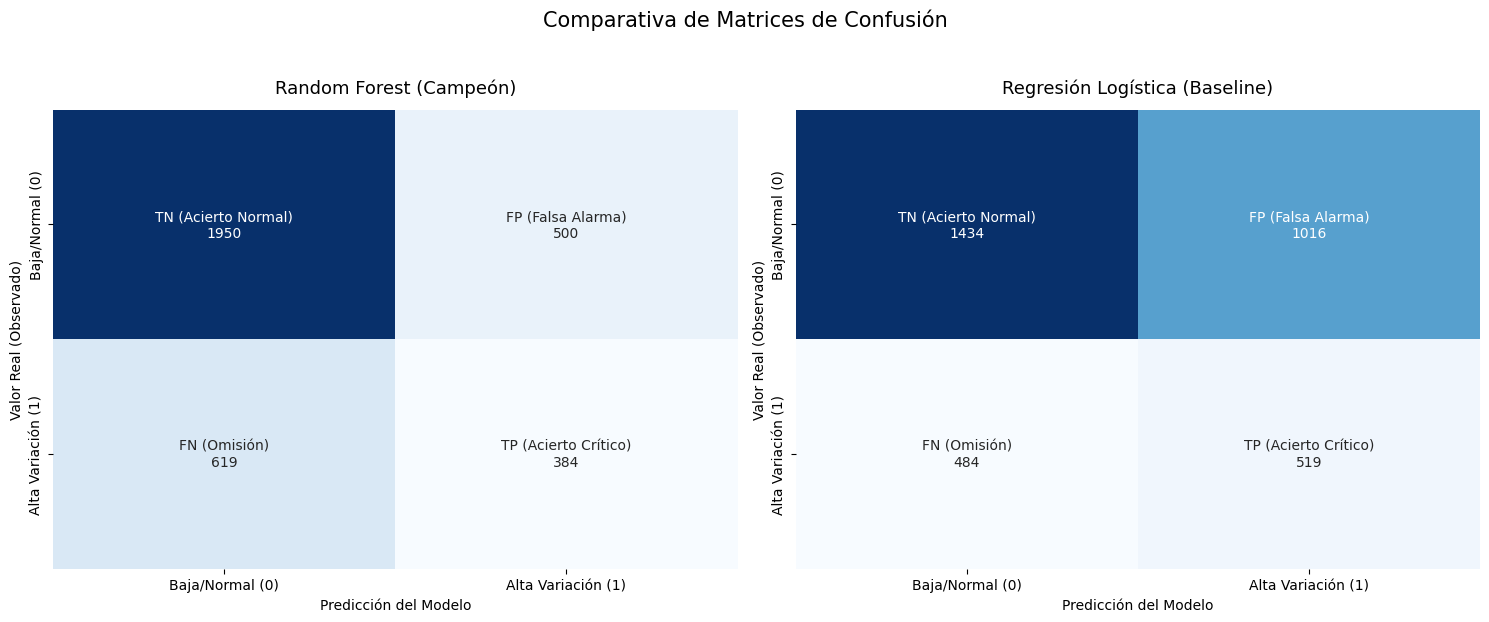

In [0]:
# 1. Extraer métricas de ambos modelos
rf_metrics = confusion_metrics(rf_predictions)
lr_metrics = confusion_metrics(lr_predictions)

# 2. Construir las matrices 2x2 para cada modelo
matriz_rf = np.array([
    [rf_metrics['tn'], rf_metrics['fp']],
    [rf_metrics['fn'], rf_metrics['tp']]
])

matriz_lr = np.array([
    [lr_metrics['tn'], lr_metrics['fp']],
    [lr_metrics['fn'], lr_metrics['tp']]
])

# 3. Preparar textos explicativos comunes
group_names = [
    "TN (Acierto Normal)", 
    "FP (Falsa Alarma)",
    "FN (Omisión)", 
    "TP (Acierto Crítico)"
]

def get_labels(matriz):
    counts = [str(val) for val in matriz.flatten()]
    labels = [f"{v1}\n{v2}" for v1, v2 in zip(group_names, counts)]
    return np.asarray(labels).reshape(2, 2)

labels_rf = get_labels(matriz_rf)
labels_lr = get_labels(matriz_lr)

# 4. Crear la figura con dos subplots (lado a lado)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Subplot 1: Random Forest
sns.heatmap(
    matriz_rf, annot=labels_rf, fmt='', cmap='Blues', cbar=False,
    annot_kws={"size": 10}, ax=axes[0],
    xticklabels=['Baja/Normal (0)', 'Alta Variación (1)'],
    yticklabels=['Baja/Normal (0)', 'Alta Variación (1)']
)
axes[0].set_title("Random Forest (Campeón)", fontsize=13, pad=12)
axes[0].set_xlabel("Predicción del Modelo", fontsize=10)
axes[0].set_ylabel("Valor Real (Observado)", fontsize=10)

# Subplot 2: Regresión Logística
sns.heatmap(
    matriz_lr, annot=labels_lr, fmt='', cmap='Blues', cbar=False,
    annot_kws={"size": 10}, ax=axes[1],
    xticklabels=['Baja/Normal (0)', 'Alta Variación (1)'],
    yticklabels=['Baja/Normal (0)', 'Alta Variación (1)']
)
axes[1].set_title("Regresión Logística (Baseline)", fontsize=13, pad=12)
axes[1].set_xlabel("Predicción del Modelo", fontsize=10)
axes[1].set_ylabel("Valor Real (Observado)", fontsize=10)

plt.suptitle("Comparativa de Matrices de Confusión", fontsize=15, y=1.03)
plt.tight_layout()

# 5. Mostrar la gráfica combinada en Databricks
plt.show()

El random forest es mucho mas equilibrado y comete menos errores, ya que tanto los falsos negativos y falsos positivos son menores comparados con los del modelo de regresion logistica

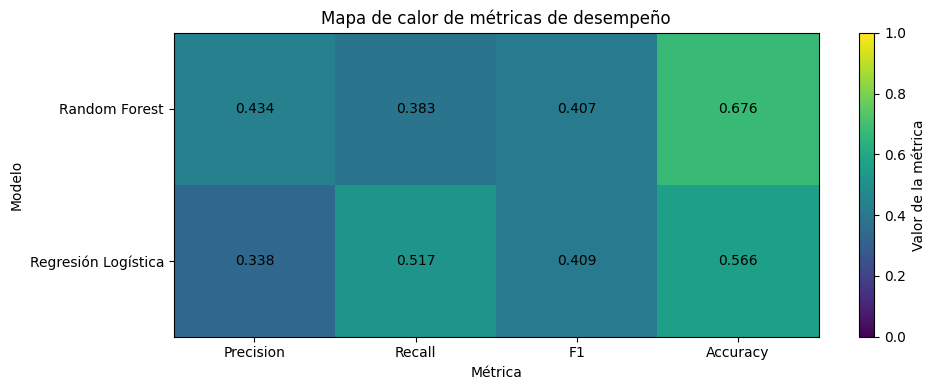

In [0]:
# Convertir Spark DataFrame a Pandas
heatmap_df = (
    summary_df
    .select(
        "Modelo",
        "Precision",
        "Recall",
        "F1",
        "Accuracy",
        
    )
    .toPandas()
    .set_index("Modelo")
)

# Crear figura
fig, ax = plt.subplots(figsize=(10, 4))

# Crear mapa de calor
im = ax.imshow(
    heatmap_df.values,
    aspect="auto",
    vmin=0,
    vmax=1
)

# Ejes
ax.set_xticks(np.arange(len(heatmap_df.columns)))
ax.set_xticklabels(heatmap_df.columns)

ax.set_yticks(np.arange(len(heatmap_df.index)))
ax.set_yticklabels(heatmap_df.index)

# Valores dentro de cada celda
for i in range(heatmap_df.shape[0]):
    for j in range(heatmap_df.shape[1]):
        ax.text(
            j,
            i,
            f"{heatmap_df.iloc[i, j]:.3f}",
            ha="center",
            va="center"
        )

# Títulos
ax.set_title("Mapa de calor de métricas de desempeño")
ax.set_xlabel("Métrica")
ax.set_ylabel("Modelo")

# Escala
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Valor de la métrica")

plt.tight_layout()
plt.show()

Se confirma que Random Forest presenta una mayor exactitud global (67.6%) frente a la Regresión Logística (56.6%), la disminución de los falsos positivos está respaldada por su mayor precisión (43.4% frente a 33.8%), no por el Recall. De hecho, el Recall más bajo del Random Forest (38.3% frente al 51.7% del modelo base) refleja un aumento en los falsos negativos; es decir, omite más casos reales de alta variación, mientras que su superioridad en la métrica de precisión es la que verdaderamente demuestra su capacidad matemática para evitar la generación de falsas alarmas.

In [0]:
baseline_metrics = confusion_metrics(baseline_predictions)

baseline_result = (
    "Baseline_majority_class",
    baseline_metrics["accuracy"],
    baseline_metrics["precision"],
    baseline_metrics["recall"],
    baseline_metrics["f1"],
    None,
    None,
    baseline_metrics["tp"],
    baseline_metrics["fp"],
    baseline_metrics["fn"],
    baseline_metrics["tn"],
)

In [0]:
results = [
    baseline_result,
    evaluate_model(lr_predictions, "LogisticRegression"),
    evaluate_model(rf_predictions, "RandomForest"),
]

metrics_schema = StructType(
    [
        StructField("model", StringType(), False),
        StructField("accuracy", DoubleType(), True),
        StructField("precision", DoubleType(), True),
        StructField("recall", DoubleType(), True),
        StructField("f1", DoubleType(), True),
        StructField("roc_auc", DoubleType(), True),
        StructField("pr_auc", DoubleType(), True),
        StructField("tp", LongType(), True),
        StructField("fp", LongType(), True),
        StructField("fn", LongType(), True),
        StructField("tn", LongType(), True),
    ]
)

metrics_df = spark.createDataFrame(results, schema=metrics_schema)
display(metrics_df.orderBy(F.desc("f1")))

model,accuracy,precision,recall,f1,roc_auc,pr_auc,tp,fp,fn,tn
LogisticRegression,0.5655951346655083,0.33811074918566775,0.5174476570289133,0.40898345153664306,0.5775970049036557,0.3948094690764543,519,1016,484,1434
RandomForest,0.6759339704604691,0.4343891402714932,0.382851445663011,0.40699523052464226,0.6012269314505471,0.4352690467182955,384,500,619,1950
Baseline_majority_class,0.7095279467130032,0.0,0.0,0.0,null,null,0,0,1003,2450


#### 12.1 Gráfico curva ROC comparativa

In [0]:
target_col = "target_high_variation_next_month"

# 1. Extraer probabilidades
pdf_rf = (
    rf_predictions
    .select(
        F.col(target_col).cast("double").alias(target_col),
        vector_to_array("probability")[1].alias("prob_1")
    )
    .dropna()
    .toPandas()
)

pdf_lr = (
    lr_predictions
    .select(
        F.col(target_col).cast("double").alias(target_col),
        vector_to_array("probability")[1].alias("prob_1")
    )
    .dropna()
    .toPandas()
)

# 2. Calcular ROC y AUC
fpr_rf, tpr_rf, _ = roc_curve(pdf_rf[target_col], pdf_rf["prob_1"])
auc_rf = auc(fpr_rf, tpr_rf)

fpr_lr, tpr_lr, _ = roc_curve(pdf_lr[target_col], pdf_lr["prob_1"])
auc_lr = auc(fpr_lr, tpr_lr)

# 3. Muestreo de puntos (evita congelar el navegador si hay miles de filas)
max_pts = 1000
step_rf = max(1, len(fpr_rf) // max_pts)
step_lr = max(1, len(fpr_lr) // max_pts)

# 4. Crear figura
fig_roc = go.Figure()

fig_roc.add_trace(go.Scatter(
    x=fpr_rf[::step_rf],
    y=tpr_rf[::step_rf],
    mode="lines",
    name=f"Random Forest (AUC = {auc_rf:.3f})",
    line=dict(color="#2ca02c", width=3)
))

fig_roc.add_trace(go.Scatter(
    x=fpr_lr[::step_lr],
    y=tpr_lr[::step_lr],
    mode="lines",
    name=f"Regresión Logística (AUC = {auc_lr:.3f})",
    line=dict(color="#ff7f0e", width=3)
))

fig_roc.add_trace(go.Scatter(
    x=[0, 1],
    y=[0, 1],
    mode="lines",
    name="Aleatorio (AUC = 0.500)",
    line=dict(color="black", width=2, dash="dash")
))

fig_roc.update_layout(
    title="Curva ROC Comparativa: Random Forest vs. Regresión Logística",
    xaxis_title="Tasa de Falsos Positivos (FPR)",
    yaxis_title="Tasa de Verdaderos Positivos (TPR)",
    legend=dict(x=0.55, y=0.1, bgcolor="rgba(255, 255, 255, 0.8)"),
    hovermode="x unified",
    width=800,
    height=600
)

fig_roc.update_xaxes(range=[0, 1], constrain="domain")
fig_roc.update_yaxes(range=[0, 1], scaleanchor="x", scaleratio=1)

# 5. Renderizar forzando HTML (Sustituye a display(fig_roc))
displayHTML(fig_roc.to_html(include_plotlyjs='cdn', full_html=False))

### Evaluación y Comparación de Modelos: Curva ROC

En esta sección se evalúa y compara el rendimiento predictivo de los modelos de clasificación entrenados utilizando la **Curva ROC** y su respectiva métrica de **Área Bajo la Curva (AUC)**

* **Random Forest (AUC = 0.601):** Muestra un mejor rendimiento global, situándose por encima de la línea base y superando al modelo lineal en la mayoría de los umbrales de clasificación.
* **Regresión Logística (AUC = 0.578):** Presenta un desempeño predictivo ligeramente inferior, aunque se mantiene por encima del modelo completamente aleatorio.
* **Línea Base / Aleatorio (AUC = 0.500):** Representado por la línea diagonal punteada, indica el rendimiento esperado por puro azar.

**Conclusión del análisis:** El modelo de **Random Forest** logra una mejor discriminación de las clases en comparación con la **Regresión Logística**, reflejado en un valor de AUC superior para este conjunto de datos.

#### 12.2. Matrices de confusión

Las matrices permiten observar directamente los verdaderos positivos, falsos positivos, falsos negativos y verdaderos negativos de cada modelo.

Matriz de confusión de regresión logistica

In [0]:
display(
    lr_predictions
    .groupBy("target_high_variation_next_month", "prediction")
    .count()
    .orderBy("target_high_variation_next_month", "prediction")
)

target_high_variation_next_month,prediction,count
0.0,0.0,1434
0.0,1.0,1016
1.0,0.0,484
1.0,1.0,519


Matriz de confusión Random Forest

In [0]:
display(
    rf_predictions
    .groupBy("target_high_variation_next_month", "prediction")
    .count()
    .orderBy("target_high_variation_next_month", "prediction")
)

target_high_variation_next_month,prediction,count
0.0,0.0,1950
0.0,1.0,500
1.0,0.0,619
1.0,1.0,384


### 13. Importancia de variables del Random Forest

La importancia indica qué características fueron más utilizadas por los árboles para separar las observaciones. Debe interpretarse como relevancia predictiva dentro del modelo, no como causalidad.

In [0]:
def get_vector_feature_names(df, vector_col="features"):
    """Extrae los nombres de atributos desde el metadata del vector Spark ML."""
    attrs = (
        df.schema[vector_col]
        .metadata
        .get("ml_attr", {})
        .get("attrs", {})
    )

    indexed_names = {}
    for attr_group in attrs.values():
        for attr in attr_group:
            indexed_names[int(attr["idx"])] = attr["name"]

    if not indexed_names:
        return []

    return [
        indexed_names.get(i, f"feature_{i}")
        for i in range(max(indexed_names) + 1)
    ]


rf_classifier = rf_model.stages[-1]
importance_values = rf_classifier.featureImportances.toArray().tolist()
rf_feature_names = get_vector_feature_names(rf_predictions)

if len(rf_feature_names) != len(importance_values):
    rf_feature_names = [
        f"feature_{i}"
        for i in range(len(importance_values))
    ]

feature_importance_rows = [
    (name, float(importance))
    for name, importance
    in zip(rf_feature_names, importance_values)
]

feature_importance_df = spark.createDataFrame(
    feature_importance_rows,
    ["feature", "importance"],
)

display(
    feature_importance_df
    .orderBy(F.desc("importance"))
)

feature,importance
cases_vs_ma_14,0.19051035879927164
cases_vs_ma_7,0.16391978508867333
change_7m,0.11682141447639267
change_1m,0.1097036350283651
change_3m,0.09773925086523633
night_cases_vs_ma_7,0.057973456608299764
month,0.056049871792047574
night_cases_change_1m,0.03795108332075787
quarter,0.033026373524469764
volatility_7m,0.019581088144866893


In [0]:
display(
    feature_importance_df
    .filter(
        ~F.col("feature").startswith("series_ohe_")
    )
    .orderBy(F.desc("importance"))
)

feature,importance
cases_vs_ma_14,0.19051035879927164
cases_vs_ma_7,0.16391978508867333
change_7m,0.11682141447639267
change_1m,0.1097036350283651
change_3m,0.09773925086523633
night_cases_vs_ma_7,0.057973456608299764
month,0.056049871792047574
night_cases_change_1m,0.03795108332075787
quarter,0.033026373524469764
volatility_7m,0.019581088144866893


Databricks visualization. Run in Databricks to view.

### 14. Comportamiento del Random Forest por hecho y localidad

Se compara la proporción real de observaciones positivas con la proporción clasificada como positiva. Estas tablas sirven para revisar si el modelo se comporta de manera diferente entre hechos o territorios.

No deben interpretarse como un ranking de seguridad de las localidades.

In [0]:
display(
    rf_predictions
    .groupBy("hecho")
    .agg(
        F.count("*").alias("records"),
        F.round(
            F.avg("target_high_variation_next_month"),
            4,
        ).alias("actual_high_variation_rate"),
        F.round(
            F.avg("prediction"),
            4,
        ).alias("predicted_high_variation_rate"),
    )
    .orderBy("hecho")
)

hecho,records,actual_high_variation_rate,predicted_high_variation_rate
DELITOS SEXUALES,361,0.3269,0.2936
EXTORSION,337,0.2344,0.3442
HOMICIDIOS,266,0.2481,0.3647
HURTO A COMERCIO,361,0.3518,0.313
HURTO A PERSONAS,361,0.3102,0.1551
HURTO A RESIDENCIAS,361,0.3075,0.1994
HURTO AUTOMOTORES,342,0.2602,0.3012
HURTO MOTOCICLETAS,342,0.2778,0.2749
LESIONES PERSONALES,361,0.2742,0.1357
VIOLENCIA INTRAFAMILIAR,361,0.2964,0.2161


In [0]:
display(
    rf_predictions
    .groupBy("localidad")
    .agg(
        F.count("*").alias("records"),
        F.round(
            F.avg("target_high_variation_next_month"),
            4,
        ).alias("actual_high_variation_rate"),
        F.round(
            F.avg("prediction"),
            4,
        ).alias("predicted_high_variation_rate"),
    )
    .orderBy("localidad")
)

localidad,records,actual_high_variation_rate,predicted_high_variation_rate
ANTONIO NARIÑO,171,0.3743,0.3216
BARRIOS UNIDOS,171,0.269,0.2222
BOSA,190,0.3474,0.2158
CANDELARIA,128,0.2734,0.4063
CHAPINERO,171,0.2164,0.2047
CIUDAD BOLÍVAR,190,0.3316,0.2211
ENGATIVÁ,190,0.2737,0.2053
FONTIBÓN,190,0.2842,0.2211
KENNEDY,190,0.2474,0.2053
LOS MÁRTIRES,190,0.2895,0.3737


### 15. Probabilidad estimada de alta variación

Random Forest genera una probabilidad para cada clase. Se extrae la probabilidad asociada con la clase positiva para ordenar las observaciones según la confianza del modelo.

In [0]:
from pyspark.ml.functions import vector_to_array

rf_probabilities = (
    rf_predictions
    .withColumn(
        "prob_high_variation",
        vector_to_array("probability")[1],
    )
)

display(
    rf_probabilities.select(
        "series_id",
        "localidad",
        "hecho",
        "date",
        "next_date",
        "cases",
        "next_cases",
        "target_high_variation_next_month",
        "prob_high_variation",
        "prediction",
    )
    .orderBy(F.desc("prob_high_variation"))
)

series_id,localidad,hecho,date,next_date,cases,next_cases,target_high_variation_next_month,prob_high_variation,prediction
ANTONIO NARIÑO | DELITOS SEXUALES,ANTONIO NARIÑO,DELITOS SEXUALES,2026-04-01,2026-05-01,0,13,1.0,0.7976002046955197,1.0
SANTA FE | HURTO A COMERCIO,SANTA FE,HURTO A COMERCIO,2025-12-01,2026-01-01,4,24,1.0,0.7905724767382926,1.0
CANDELARIA | EXTORSION,CANDELARIA,EXTORSION,2025-02-01,2025-03-01,0,1,0.0,0.7894864208982767,1.0
CIUDAD BOLÍVAR | EXTORSION,CIUDAD BOLÍVAR,EXTORSION,2025-10-01,2025-11-01,0,8,1.0,0.7857096361870232,1.0
ENGATIVÁ | VIOLENCIA INTRAFAMILIAR,ENGATIVÁ,VIOLENCIA INTRAFAMILIAR,2025-12-01,2026-01-01,104,474,1.0,0.7852571484853071,1.0
RAFAEL URIBE URIBE | DELITOS SEXUALES,RAFAEL URIBE URIBE,DELITOS SEXUALES,2025-12-01,2026-01-01,6,25,1.0,0.7851858503326663,1.0
SANTA FE | HOMICIDIOS,SANTA FE,HOMICIDIOS,2025-06-01,2025-07-01,1,5,1.0,0.7849197050052716,1.0
BARRIOS UNIDOS | DELITOS SEXUALES,BARRIOS UNIDOS,DELITOS SEXUALES,2025-12-01,2026-01-01,2,11,1.0,0.7833392469760365,1.0
CANDELARIA | VIOLENCIA INTRAFAMILIAR,CANDELARIA,VIOLENCIA INTRAFAMILIAR,2025-12-01,2026-01-01,4,16,1.0,0.7827957817472745,1.0
CHAPINERO | VIOLENCIA INTRAFAMILIAR,CHAPINERO,VIOLENCIA INTRAFAMILIAR,2025-12-01,2026-01-01,19,101,1.0,0.7820654005447404,1.0


Databricks visualization. Run in Databricks to view.

Databricks visualization. Run in Databricks to view.

### 16. Interpretación de resultados

En la ejecución realizada en Databricks con este conjunto de datos, el baseline alcanzó una `accuracy` cercana a 0,71. Sin embargo, obtuvo `recall = 0`: al predecir siempre la clase mayoritaria no identificó ningún episodio de alta variación. Este resultado muestra por qué la exactitud no puede utilizarse de manera aislada.

La Regresión Logística obtuvo aproximadamente `precision = 0,34`, `recall = 0,52` y `F1 = 0,41`. Su principal fortaleza fue la sensibilidad: logró recuperar una mayor proporción de los episodios positivos, aunque produjo más falsos positivos.

Random Forest obtuvo aproximadamente `precision = 0,43`, `recall = 0,38`, `F1 = 0,41`, `ROC AUC = 0,60` y `PR AUC = 0,44`. Fue más selectivo que la Regresión Logística y mostró una capacidad de discriminación algo mayor, pero dejó sin identificar una proporción mayor de episodios positivos.

Por eso no existe un ganador absoluto. Si el interés principal fuera reconocer la mayor cantidad posible de meses con cambios altos, la Regresión Logística resulta más sensible. Si se busca reducir falsas alarmas y ordenar mejor las observaciones positivas, Random Forest presenta ventajas.

Los valores de AUC muestran que existe cierta señal predictiva en la historia reciente, pero esa señal es moderada. Los modelos superan al baseline en su capacidad para identificar la clase positiva, aunque todavía están lejos de separar con alta precisión los meses normales de los meses con cambios inusualmente grandes.

En Random Forest, las variables con mayor importancia fueron `cases_vs_ma_14`, `cases_vs_ma_7`, `change_7m`, `change_1m` y `change_3m`. Esto sugiere que resulta especialmente informativo conocer qué tan lejos se encuentra el conteo actual de su tendencia reciente y cómo venía cambiando la serie en distintos horizontes.

Debe recordarse que la etiqueta corresponde a **alta variación absoluta**. Una reducción fuerte y un aumento fuerte pueden pertenecer a la misma clase positiva. Por lo tanto, el modelo no predice un aumento de la criminalidad: identifica condiciones asociadas con movimientos mensuales grandes respecto de la historia de cada serie.

Como ejemplo de la predicción realizada, se analiza el comportamiento del hurto a personas. Los resultados del modelo sugieren que para el mes siguiente al periodo analizado, podría presentarse una disminución leve en el número de casos en las diferentes localidades de Bogotá. No obstante, esta variación no sería significativa y debe interpretarse como una proyección basada en los patrones históricos identificados en la serie de tiempo. Cabe resaltar que la localidad de Rafael Uribe Uribe presentaría un posible aumento en los casos de hurto. Este constituye uno de los múltiples ejemplos que pueden identificarse a partir del modelo desarrollado, cuyos filtros permiten evidenciar los comportamientos específicos por localidad y por tipología de delito.


### 17. Limitaciones

SIEDCO es una fuente administrativa y refleja los hechos registrados en el sistema. Los conteos pueden estar afectados por dinámicas de denuncia, registro o clasificación y no representan necesariamente la totalidad de hechos ocurridos.

El análisis utiliza conteos y no tasas poblacionales. Por esta razón, las diferencias entre localidades no deben interpretarse directamente como diferencias de riesgo.

El modelo utiliza únicamente información histórica de la propia base. No incorpora población, movilidad, actividad económica, eventos, intervenciones institucionales u otras variables externas que podrían ayudar a explicar cambios futuros.

Cuando una combinación localidad–hecho no aparece en un mes se completa con cero para mantener una secuencia mensual continua. Esta decisión supone que la ausencia de la combinación en la tabla representa ausencia de registros positivos durante ese período.

Para evitar series extremadamente esporádicas se conservan combinaciones con una historia mínima de 80 meses con registros positivos. Esto mejora la estabilidad de rezagos, medias móviles y percentiles, pero también restringe el universo sobre el cual se interpretan los resultados.

El umbral de la clase positiva se calcula por serie. Un cambio considerado alto en una serie pequeña puede involucrar muchos menos casos que un cambio equivalente en una serie de gran volumen.

Finalmente, se comparan dos modelos con parámetros fijos. No se realiza búsqueda de hiperparámetros ni validación temporal con múltiples ventanas, por lo que el ejercicio debe interpretarse como una aproximación inicial al problema.

### 18. Reflexión final

El resultado del ejercicio depende tanto del procesamiento como del algoritmo utilizado.

Bronze permite conservar una copia trazable de la fuente. Silver resuelve el grano original de SIEDCO y construye una secuencia mensual consistente. Gold transforma esa secuencia en variables históricas sin utilizar el mes futuro como predictor. Después, la separación cronológica y el cálculo del percentil exclusivamente con entrenamiento permiten evaluar los modelos de una manera coherente con el problema temporal.

También se observa que una métrica aislada puede llevar a conclusiones equivocadas. El baseline obtiene una exactitud alta simplemente porque la clase 0 es mayoritaria, pero no identifica ningún episodio positivo. Al revisar precision, recall, F1, ROC AUC, PR AUC y matrices de confusión se obtiene una lectura mucho más completa.

En este caso, el comportamiento reciente de las series contiene información útil sobre la variación del mes siguiente, aunque no suficiente para construir un clasificador de alta precisión. Esa conclusión también es valiosa: en analítica predictiva, reconocer el alcance y las limitaciones de los datos es tan importante como entrenar el modelo.

### 19. Referencias

Balusamy, B., Nandhini Abirami, R., Kadry, S., & Gandomi, A. H. (2021). *Big data: Concepts, technology, and architecture*. John Wiley & Sons. https://doi.org/10.1002/9781119701859

Databricks Documentation: Delta Lake Guide & Spark MLlib Pipelines. 

Apache Software Foundation. (s. f.). *Apache Spark documentation*. https://spark.apache.org/docs/latest/

Secretaría Distrital de Seguridad, Convivencia y Justicia. (2026). *SIEDCO* delitos de alto impacto. Información consultada el 3 de agosto de 2026, con corte al 31 de julio de 2026.